In [ ]:
# Install required packages
!pip install pandas numpy matplotlib seaborn scipy statsmodels

# Import all necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Configuration for better visualization
%matplotlib inline
plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 8)
pd.set_option('display.max_columns', None)

print("All libraries imported successfully")

All libraries imported successfully


In [ ]:
print("STEP 1: DATA LOADING WITH NUMPY GENFROMTXT")

# Load data using NumPy's genfromtxt as specified in requirements
data_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/parkinsons/telemonitoring/parkinsons_updrs.data"

try:
    # First attempt with genfromtxt
    print("Attempting to load data with numpy.genfromtxt...")
    data_numpy = np.genfromtxt(data_url, delimiter=',', names=True, dtype=None, encoding='utf-8')
    print("Successfully loaded with numpy.genfromtxt")

    # Convert to pandas DataFrame for easier analysis
    df = pd.DataFrame(data_numpy)
    print("Converted to pandas DataFrame")

except Exception as e:
    print("numpy.genfromtxt failed:", str(e))
    print("Using pandas.read_csv as allowed by project requirements...")

    # Fallback to pandas
    df = pd.read_csv(data_url)
    print("Successfully loaded with pandas.read_csv")

# Display dataset information
print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
print("Number of records:", df.shape[0])
print("Number of features:", df.shape[1])

print("First 5 records:")
display(df.head())

Streaming output truncated to the last 5000 lines.
    Line #884 (got 22 columns instead of 21)
    Line #885 (got 22 columns instead of 21)
    Line #886 (got 22 columns instead of 21)
    Line #887 (got 22 columns instead of 21)
    Line #888 (got 22 columns instead of 21)
    Line #889 (got 22 columns instead of 21)
    Line #890 (got 22 columns instead of 21)
    Line #891 (got 22 columns instead of 21)
    Line #892 (got 22 columns instead of 21)
    Line #893 (got 22 columns instead of 21)
    Line #894 (got 22 columns instead of 21)
    Line #895 (got 22 columns instead of 21)
    Line #896 (got 22 columns instead of 21)
    Line #897 (got 22 columns instead of 21)
    Line #898 (got 22 columns instead of 21)
    Line #899 (got 22 columns instead of 21)
    Line #900 (got 22 columns instead of 21)
    Line #901 (got 22 columns instead of 21)
    Line #902 (got 22 columns instead of 21)
    Line #903 (got 22 columns instead of 21)
    Line #904 (got 22 columns instead of 21)
    

,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,0.01204,0.02565,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,0.00395,0.02024,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,0.00616,0.01675,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,0.00573,0.02309,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,0.00278,0.01703,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


In [ ]:
print("DATA TYPE ANALYSIS")

# Get detailed information about data types
print("Dataset Info:")
df.info()

print("Data types for each column:")
print(df.dtypes)

# Separate numeric and non-numeric columns
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()
non_numeric_columns = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numeric columns:", len(numeric_columns))
print("Non-numeric columns:", len(non_numeric_columns))

if non_numeric_columns:
    print("Non-numeric columns found:", non_numeric_columns)
else:
    print("All columns are numeric")

# Display sample values
print("Sample values from first record:")
for column in df.columns[:8]:  # Show first 8 columns
    print(f"{column}: {df[column].iloc[0]} (type: {df[column].dtype})")

DATA TYPE ANALYSIS
Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5875 entries, 0 to 5874
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subject#       5875 non-null   int64  
 1   age            5875 non-null   int64  
 2   sex            5875 non-null   int64  
 3   test_time      5875 non-null   float64
 4   motor_UPDRS    5875 non-null   float64
 5   total_UPDRS    5875 non-null   float64
 6   Jitter(%)      5875 non-null   float64
 7   Jitter(Abs)    5875 non-null   float64
 8   Jitter:RAP     5875 non-null   float64
 9   Jitter:PPQ5    5875 non-null   float64
 10  Jitter:DDP     5875 non-null   float64
 11  Shimmer        5875 non-null   float64
 12  Shimmer(dB)    5875 non-null   float64
 13  Shimmer:APQ3   5875 non-null   float64
 14  Shimmer:APQ5   5875 non-null   float64
 15  Shimmer:APQ11  5875 non-null   float64
 16  Shimmer:DDA    5875 non-null   float64
 17  NHR            5875

In [ ]:
print("MISSING VALUES ANALYSIS")

# Check for missing values
missing_data = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_data,
    'Missing Percentage': missing_percentage
})

print("Total missing values in dataset:", df.isnull().sum().sum())
print("Number of columns with missing values:", len(missing_summary[missing_summary['Missing Count'] > 0]))

if df.isnull().sum().sum() > 0:
    print("Columns with missing values:")
    display(missing_summary[missing_summary['Missing Count'] > 0])
else:
    print("No missing values found in the dataset")

# Check for alternative missing value representations
print("Checking for alternative missing value representations...")
missing_representations = ['NA', 'N/A', 'null', 'NULL', 'NaN', '?', '-', '--', '']
found_alternative_missing = False

for column in df.columns:
    for representation in missing_representations:
        count = (df[column].astype(str) == representation).sum()
        if count > 0:
            print(f"Found {count} instances of '{representation}' in column '{column}'")
            found_alternative_missing = True

if not found_alternative_missing:
    print("No alternative missing value representations found")

MISSING VALUES ANALYSIS
Total missing values in dataset: 0
Number of columns with missing values: 0
No missing values found in the dataset
Checking for alternative missing value representations...
No alternative missing value representations found


In [ ]:
print("STATISTICAL SUMMARY")

# Generate descriptive statistics
print("Descriptive statistics for all numerical columns:")
display(df.describe())

# Additional statistics with more percentiles
print("Detailed statistics with additional percentiles:")
detailed_stats = df.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
display(detailed_stats)

# Skewness and kurtosis analysis
print("Distribution analysis - Skewness and Kurtosis:")
distribution_stats = pd.DataFrame({
    'Skewness': df[numeric_columns].skew(),
    'Kurtosis': df[numeric_columns].kurtosis()
})
display(distribution_stats.sort_values('Skewness', key=abs, ascending=False).head(10))

print("Interpretation:")
print("Skewness near 0: symmetrical distribution")
print("Skewness > 0: right-skewed distribution")
print("Skewness < 0: left-skewed distribution")
print("Kurtosis near 0: normal distribution")
print("Kurtosis > 0: heavy-tailed distribution")
print("Kurtosis < 0: light-tailed distribution")

STATISTICAL SUMMARY
Descriptive statistics for all numerical columns:


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
count,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000
mean,21.494128,64.804936,0.317787,92.863722,21.296229,29.018942,0.006154,0.000044,0.002987,0.003277,0.008962,0.034035,0.310960,0.017156,0.020144,0.027481,0.051467,0.032120,21.679495,0.541473,0.653240,0.219589
std,12.372279,8.821524,0.465656,53.445602,8.129282,10.700283,0.005624,0.000036,0.003124,0.003732,0.009371,0.025835,0.230254,0.013237,0.016664,0.019986,0.039711,0.059692,4.291096,0.100986,0.070902,0.091498
min,1.000000,36.000000,0.000000,-4.262500,5.037700,7.000000,0.000830,0.000002,0.000330,0.000430,0.000980,0.003060,0.026000,0.001610,0.001940,0.002490,0.004840,0.000286,1.659000,0.151020,0.514040,0.021983
25%,10.000000,58.000000,0.000000,46.847500,15.000000,21.371000,0.003580,0.000022,0.001580,0.001820,0.004730,0.019120,0.175000,0.009280,0.010790,0.015665,0.027830,0.010955,19.406000,0.469785,0.596180,0.156340
50%,22.000000,65.000000,0.000000,91.523000,20.871000,27.576000,0.004900,0.000035,0.002250,0.002490,0.006750,0.027510,0.253000,0.013700,0.015940,0.022710,0.041110,0.018448,21.920000,0.542250,0.643600,0.205500
75%,33.000000,72.000000,1.000000,138.445000,27.596500,36.399000,0.006800,0.000053,0.003290,0.003460,0.009870,0.039750,0.365000,0.020575,0.023755,0.032715,0.061735,0.031463,24.444000,0.614045,0.711335,0.264490
max,42.000000,85.000000,1.000000,215.490000,39.511000,54.992000,0.099990,0.000446,0.057540,0.069560,0.172630,0.268630,2.107000,0.162670,0.167020,0.275460,0.488020,0.748260,37.875000,0.966080,0.865600,0.731730


Detailed statistics with additional percentiles:


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
count,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000
mean,21.494128,64.804936,0.317787,92.863722,21.296229,29.018942,0.006154,0.000044,0.002987,0.003277,0.008962,0.034035,0.310960,0.017156,0.020144,0.027481,0.051467,0.032120,21.679495,0.541473,0.653240,0.219589
std,12.372279,8.821524,0.465656,53.445602,8.129282,10.700283,0.005624,0.000036,0.003124,0.003732,0.009371,0.025835,0.230254,0.013237,0.016664,0.019986,0.039711,0.059692,4.291096,0.100986,0.070902,0.091498
min,1.000000,36.000000,0.000000,-4.262500,5.037700,7.000000,0.000830,0.000002,0.000330,0.000430,0.000980,0.003060,0.026000,0.001610,0.001940,0.002490,0.004840,0.000286,1.659000,0.151020,0.514040,0.021983
1%,1.000000,36.000000,0.000000,4.420800,6.000000,7.088300,0.001740,0.000008,0.000690,0.000847,0.002075,0.008534,0.077000,0.003480,0.004307,0.006744,0.010447,0.002043,6.292540,0.308339,0.529632,0.061975
5%,2.700000,49.000000,0.000000,12.426000,8.467100,12.469000,0.002320,0.000012,0.000990,0.001170,0.002960,0.012050,0.111000,0.005407,0.006517,0.009540,0.016214,0.004124,14.935500,0.375774,0.549568,0.099762
25%,10.000000,58.000000,0.000000,46.847500,15.000000,21.371000,0.003580,0.000022,0.001580,0.001820,0.004730,0.019120,0.175000,0.009280,0.010790,0.015665,0.027830,0.010955,19.406000,0.469785,0.596180,0.156340
50%,22.000000,65.000000,0.000000,91.523000,20.871000,27.576000,0.004900,0.000035,0.002250,0.002490,0.006750,0.027510,0.253000,0.013700,0.015940,0.022710,0.041110,0.018448,21.920000,0.542250,0.643600,0.205500
75%,33.000000,72.000000,1.000000,138.445000,27.596500,36.399000,0.006800,0.000053,0.003290,0.003460,0.009870,0.039750,0.365000,0.020575,0.023755,0.032715,0.061735,0.031463,24.444000,0.614045,0.711335,0.264490
95%,41.000000,78.000000,1.000000,175.500000,35.034600,47.257000,0.013416,0.000108,0.007029,0.006903,0.021094,0.074321,0.681000,0.039197,0.044909,0.060179,0.117591,0.086838,27.930000,0.701270,0.773601,0.396067


Distribution analysis - Skewness and Kurtosis:


,Skewness,Kurtosis
Jitter:PPQ5,7.586205,81.566374
Jitter:RAP,6.945438,78.534581
Jitter:DDP,6.945376,78.532426
NHR,6.549123,52.606172
Jitter(%),6.451846,67.496559
Shimmer:APQ5,3.698061,19.244339
Shimmer:APQ11,3.406958,19.160187
Shimmer,3.312793,15.240156
Jitter(Abs),3.283075,18.155601
Shimmer(dB),3.099221,13.091042


Interpretation:
Skewness near 0: symmetrical distribution
Skewness > 0: right-skewed distribution
Skewness < 0: left-skewed distribution
Kurtosis near 0: normal distribution
Kurtosis > 0: heavy-tailed distribution
Kurtosis < 0: light-tailed distribution


In [ ]:
print("OUTLIER DETECTION")

def detect_outliers_iqr(dataframe, columns):
    """Detect outliers using IQR method"""
    outlier_summary = {}

    for col in columns:
        Q1 = dataframe[col].quantile(0.25)
        Q3 = dataframe[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = dataframe[(dataframe[col] < lower_bound) | (dataframe[col] > upper_bound)]
        outlier_count = len(outliers)
        outlier_percentage = (outlier_count / len(dataframe)) * 100

        outlier_summary[col] = {
            'Lower Bound': lower_bound,
            'Upper Bound': upper_bound,
            'Outlier Count': outlier_count,
            'Outlier Percentage': outlier_percentage,
            'Min Value': dataframe[col].min(),
            'Max Value': dataframe[col].max()
        }

    return outlier_summary

# Detect outliers for all numeric columns
outlier_results = detect_outliers_iqr(df, numeric_columns)
outlier_summary_df = pd.DataFrame(outlier_results).T
outlier_summary_df = outlier_summary_df.sort_values('Outlier Count', ascending=False)

print("Top 15 columns with most outliers:")
display(outlier_summary_df.head(15))

print("Columns with more than 10% outliers:")
high_outlier_cols = outlier_summary_df[outlier_summary_df['Outlier Percentage'] > 10]
display(high_outlier_cols)

OUTLIER DETECTION
Top 15 columns with most outliers:


,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage,Min Value,Max Value
NHR,-0.019807,0.062225,436.0,7.421277,0.000286,0.748260
Jitter:PPQ5,-0.000640,0.005920,425.0,7.234043,0.000430,0.069560
Jitter:RAP,-0.000985,0.005855,414.0,7.046809,0.000330,0.057540
Jitter:DDP,-0.002980,0.017580,413.0,7.029787,0.000980,0.172630
Jitter(%),-0.001250,0.011630,398.0,6.774468,0.000830,0.099990
Jitter(Abs),-0.000024,0.000100,366.0,6.229787,0.000002,0.000446
Shimmer,-0.011825,0.070695,333.0,5.668085,0.003060,0.268630
Shimmer(dB),-0.110000,0.650000,332.0,5.651064,0.026000,2.107000
Shimmer:APQ3,-0.007663,0.037518,332.0,5.651064,0.001610,0.162670
Shimmer:DDA,-0.023027,0.112592,331.0,5.634043,0.004840,0.488020


Columns with more than 10% outliers:


,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage,Min Value,Max Value


VISUAL OUTLIER DETECTION


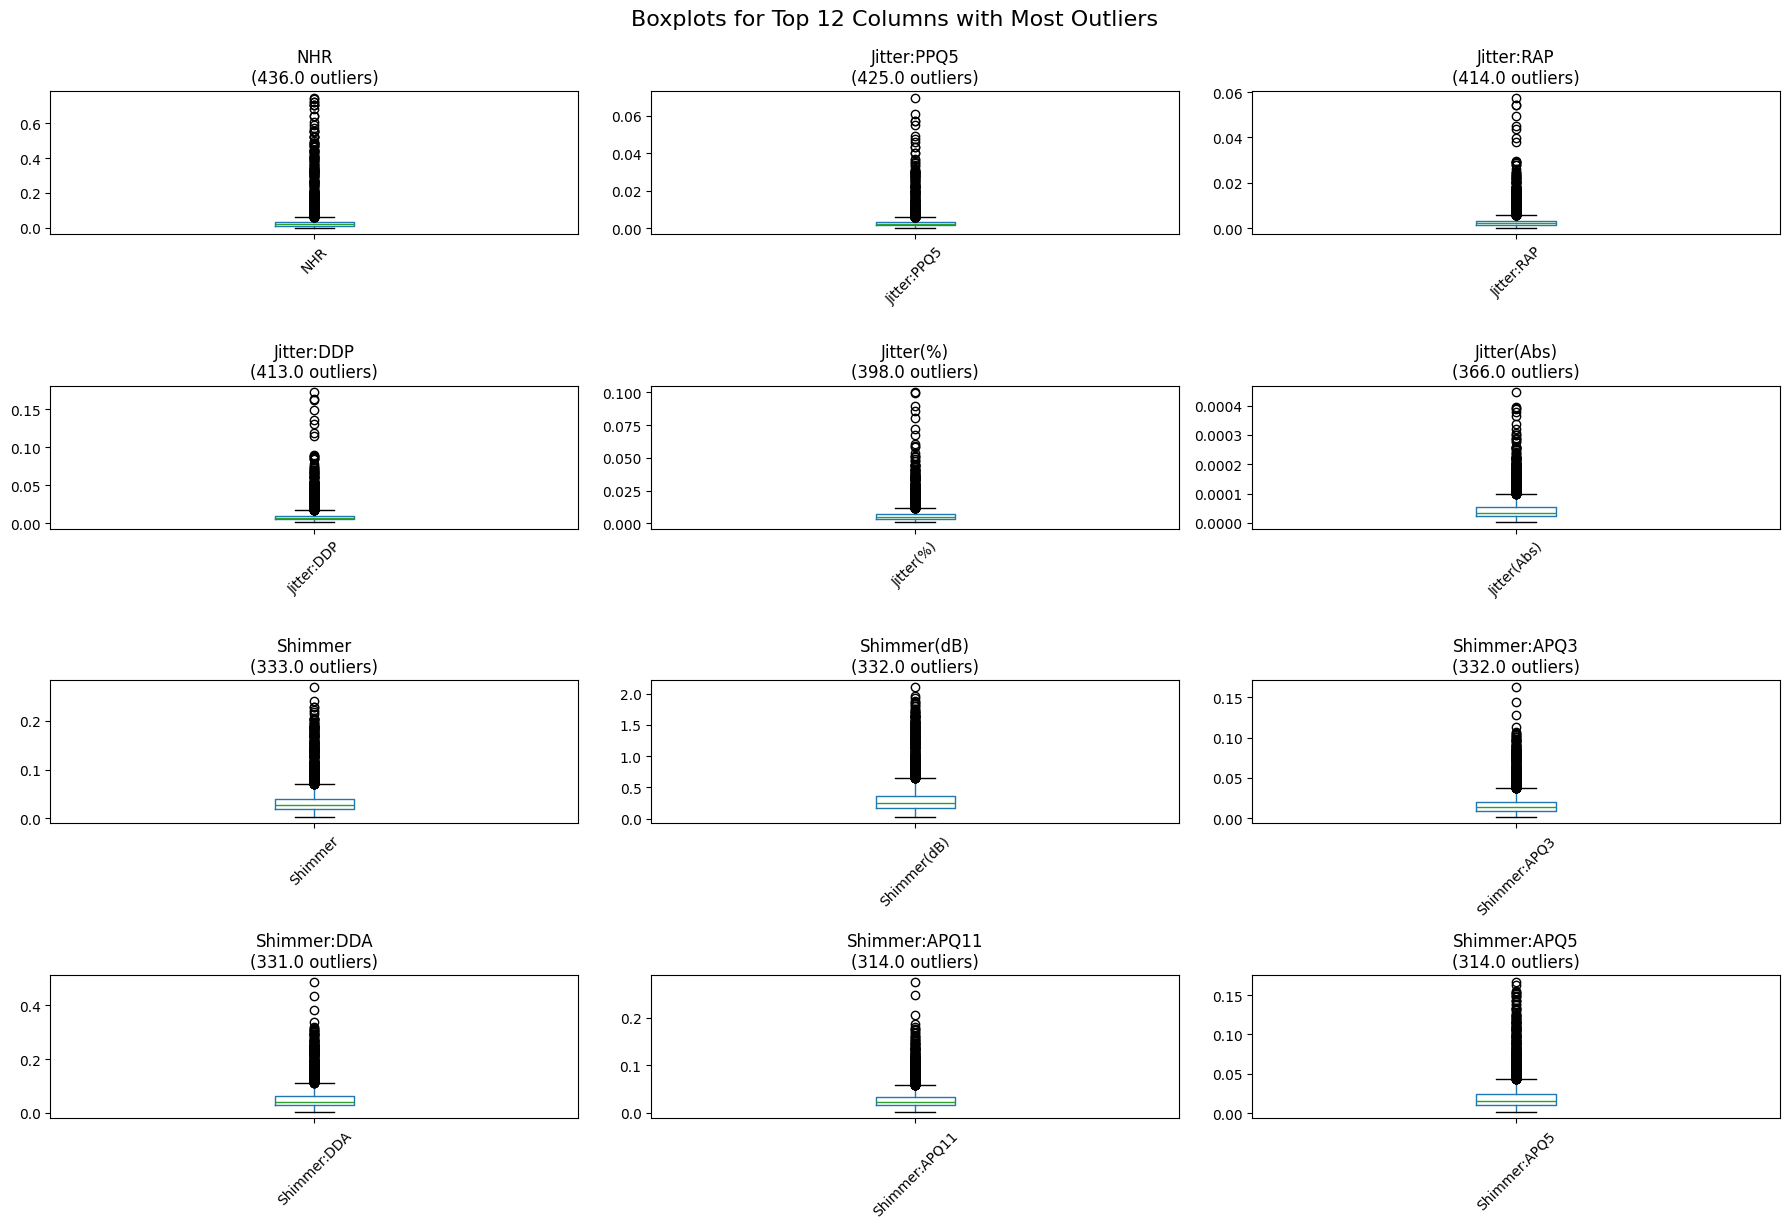

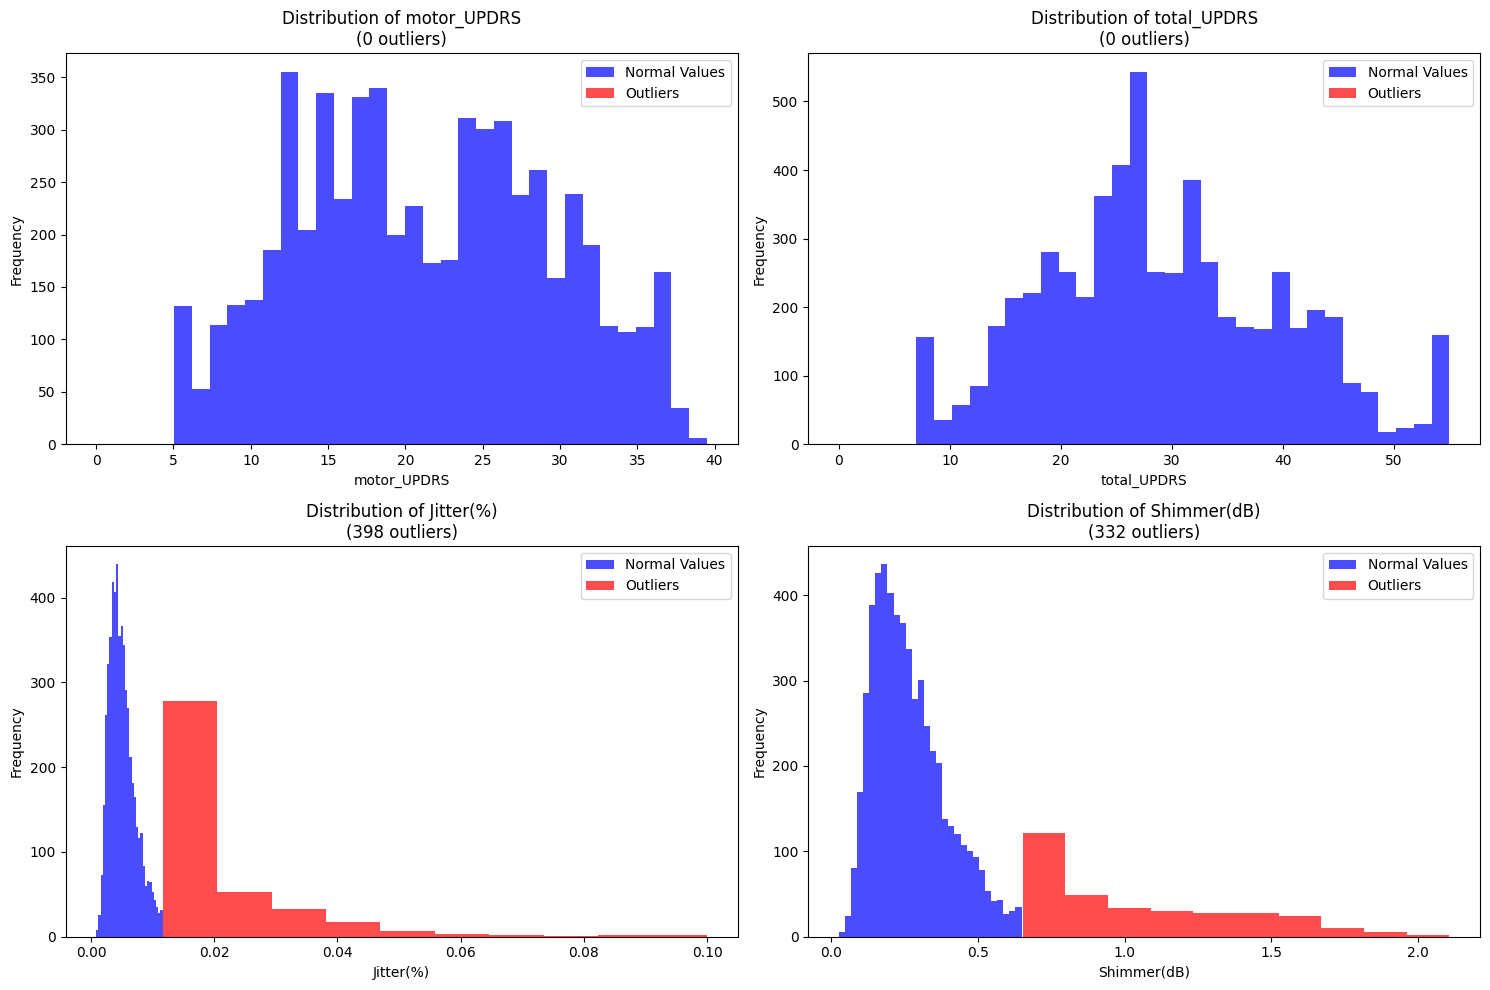

In [ ]:
print("VISUAL OUTLIER DETECTION")

# Create boxplots for top columns with outliers
top_outlier_columns = outlier_summary_df.head(12).index

fig, axes = plt.subplots(4, 3, figsize=(18, 12))
axes = axes.ravel()

for i, column in enumerate(top_outlier_columns):
    df.boxplot(column=column, ax=axes[i], grid=False)
    axes[i].set_title(f'{column}\n({outlier_summary_df.loc[column, "Outlier Count"]} outliers)')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.suptitle('Boxplots for Top 12 Columns with Most Outliers', y=1.02, fontsize=16)
plt.show()

# Histograms with outlier highlighting for key columns
key_columns = ['motor_UPDRS', 'total_UPDRS', 'Jitter(%)', 'Shimmer(dB)']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

for i, col in enumerate(key_columns):
    # Calculate IQR bounds
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    non_outliers = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

    # Plot histogram
    axes[i].hist(non_outliers[col], bins=30, alpha=0.7, label='Normal Values', color='blue')
    axes[i].hist(outliers[col], bins=10, alpha=0.7, label='Outliers', color='red')
    axes[i].set_title(f'Distribution of {col}\n({len(outliers)} outliers)')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].legend()

plt.tight_layout()
plt.show()

In [ ]:
print("DATA TRANSFORMATION AND CLEANING")

# Check if any non-numeric columns need conversion
if non_numeric_columns:
    print("Converting non-numeric columns to numeric...")
    for column in non_numeric_columns:
        print(f"Processing column: {column}")
        original_type = df[column].dtype
        unique_values = df[column].unique()

        # Try to convert to numeric
        df[column] = pd.to_numeric(df[column], errors='coerce')

        # Check conversion results
        converted_nulls = df[column].isnull().sum()
        if converted_nulls > 0:
            print(f"Warning: {converted_nulls} values could not be converted in {column}")
        else:
            print(f"Successfully converted {column} from {original_type} to numeric")

        print(f"Unique values before: {unique_values}")
        print(f"Unique values after: {df[column].unique()[:5]}...")  # Show first 5
else:
    print("All columns are already numeric - no conversion needed")

# Update numeric columns list
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()
print("Final number of numeric columns:", len(numeric_columns))

# Check for constant columns (columns with only one value)
constant_columns = []
for column in numeric_columns:
    if df[column].nunique() == 1:
        constant_columns.append(column)

if constant_columns:
    print("Constant columns found (only one unique value):", constant_columns)
else:
    print("No constant columns found")

DATA TRANSFORMATION AND CLEANING
All columns are already numeric - no conversion needed
Final number of numeric columns: 22
No constant columns found


In [ ]:
print("STEP 1 COMPLETION: DATA QUALITY REPORT")

# Create comprehensive quality report
quality_report = pd.DataFrame(index=df.columns)
quality_report['Data Type'] = df.dtypes
quality_report['Total Records'] = len(df)
quality_report['Missing Values'] = df.isnull().sum()
quality_report['Missing Percentage'] = (df.isnull().sum() / len(df)) * 100
quality_report['Unique Values'] = df.nunique()

# Add outlier information
for col in df.columns:
    if col in outlier_summary_df.index:
        quality_report.loc[col, 'Outlier Count'] = outlier_summary_df.loc[col, 'Outlier Count']
        quality_report.loc[col, 'Outlier Percentage'] = outlier_summary_df.loc[col, 'Outlier Percentage']

print("Comprehensive Data Quality Summary:")
display(quality_report)

print("KEY FINDINGS FROM STEP 1:")
print("1. Dataset contains", df.shape[0], "records and", df.shape[1], "features")
print("2. Total missing values:", df.isnull().sum().sum())
print("3. Number of columns with missing values:", len(quality_report[quality_report['Missing Values'] > 0]))
print("4. Number of columns with >5% outliers:", len(quality_report[quality_report['Outlier Percentage'] > 5]))
print("5. All data types are numeric:", len(non_numeric_columns) == 0)

print("STEP 1: DATA PREPARATION COMPLETED SUCCESSFULLY")
print("The data is now ready for Exploratory Data Analysis in Step 2")

STEP 1 COMPLETION: DATA QUALITY REPORT
Comprehensive Data Quality Summary:


,Data Type,Total Records,Missing Values,Missing Percentage,Unique Values,Outlier Count,Outlier Percentage
subject#,int64,5875,0,0.0,42,0.0,0.000000
age,int64,5875,0,0.0,23,101.0,1.719149
sex,int64,5875,0,0.0,2,0.0,0.000000
test_time,float64,5875,0,0.0,2442,0.0,0.000000
motor_UPDRS,float64,5875,0,0.0,1080,0.0,0.000000
total_UPDRS,float64,5875,0,0.0,1129,0.0,0.000000
Jitter(%),float64,5875,0,0.0,1305,398.0,6.774468
Jitter(Abs),float64,5875,0,0.0,4105,366.0,6.229787
Jitter:RAP,float64,5875,0,0.0,853,414.0,7.046809
Jitter:PPQ5,float64,5875,0,0.0,840,425.0,7.234043


KEY FINDINGS FROM STEP 1:
1. Dataset contains 5875 records and 22 features
2. Total missing values: 0
3. Number of columns with missing values: 0
4. Number of columns with >5% outliers: 12
5. All data types are numeric: True
STEP 1: DATA PREPARATION COMPLETED SUCCESSFULLY
The data is now ready for Exploratory Data Analysis in Step 2


from matplotlib import pyplot as plt
quality_report['Unique Values'].plot(kind='hist', bins=20, title='Unique Values')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
quality_report['Outlier Count'].plot(kind='hist', bins=20, title='Outlier Count')
plt.gca().spines[['top', 'right',]].set_visible(False)

...

from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(quality_report['Data Type'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(quality_report, x='Unique Values', y='Data Type', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

<string>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(quality_report['Data Type'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(quality_report, x='Outlier Count', y='Data Type', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

<string>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(quality_report['Data Type'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(quality_report, x='Outlier Percentage', y='Data Type', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

In [ ]:
print("STEP 2: EXPLORATORY DATA ANALYSIS")
print("CORRELATION ANALYSIS")

# Calculate correlation matrix
correlation_matrix = df.corr()

print("Correlation matrix dimensions:", correlation_matrix.shape)
print("Analyzing correlations among", len(correlation_matrix.columns), "features")

# Display correlation matrix preview
print("Correlation matrix preview (first 8x8):")
display(correlation_matrix.iloc[:8, :8])

# Analyze correlations with target variables
print("Top 15 features correlated with motor_UPDRS:")
motor_updrs_corr = correlation_matrix['motor_UPDRS'].abs().sort_values(ascending=False)
display(motor_updrs_corr.head(16))  # Includes motor_UPDRS itself

print("Top 15 features correlated with total_UPDRS:")
total_updrs_corr = correlation_matrix['total_UPDRS'].abs().sort_values(ascending=False)
display(total_updrs_corr.head(16))  # Includes total_UPDRS itself

# Find highly correlated feature pairs
print("Highly correlated feature pairs (absolute correlation > 0.8):")
high_corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        corr_value = abs(correlation_matrix.iloc[i, j])
        if corr_value > 0.8:
            high_corr_pairs.append((
                correlation_matrix.columns[i],
                correlation_matrix.columns[j],
                corr_value
            ))

# Sort by correlation strength
high_corr_pairs.sort(key=lambda x: x[2], reverse=True)

if high_corr_pairs:
    for i, (feat1, feat2, corr) in enumerate(high_corr_pairs[:10], 1):
        print(f"{i}. {feat1} vs {feat2}: {corr:.3f}")
else:
    print("No highly correlated pairs found (r > 0.8)")

STEP 2: EXPLORATORY DATA ANALYSIS
CORRELATION ANALYSIS
Correlation matrix dimensions: (22, 22)
Analyzing correlations among 22 features
Correlation matrix preview (first 8x8):


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs)
subject#,1.000000,-0.030864,0.286851,-0.000882,0.252919,0.253643,0.135448,0.075156
age,-0.030864,1.000000,-0.041602,0.019884,0.273665,0.310290,0.023071,0.035691
sex,0.286851,-0.041602,1.000000,-0.009805,-0.031205,-0.096559,0.051422,-0.154645
test_time,-0.000882,0.019884,-0.009805,1.000000,0.067918,0.075263,-0.022837,-0.011365
motor_UPDRS,0.252919,0.273665,-0.031205,0.067918,1.000000,0.947231,0.084816,0.050903
total_UPDRS,0.253643,0.310290,-0.096559,0.075263,0.947231,1.000000,0.074247,0.066927
Jitter(%),0.135448,0.023071,0.051422,-0.022837,0.084816,0.074247,1.000000,0.865577
Jitter(Abs),0.075156,0.035691,-0.154645,-0.011365,0.050903,0.066927,0.865577,1.000000


Top 15 features correlated with motor_UPDRS:


,motor_UPDRS
motor_UPDRS,1.000000
total_UPDRS,0.947231
age,0.273665
subject#,0.252919
PPE,0.162433
HNR,0.157029
Shimmer:APQ11,0.136560
RPDE,0.128607
DFA,0.116242
Shimmer(dB),0.110076


Top 15 features correlated with total_UPDRS:


,total_UPDRS
total_UPDRS,1.000000
motor_UPDRS,0.947231
age,0.310290
subject#,0.253643
HNR,0.162117
RPDE,0.156897
PPE,0.156195
Shimmer:APQ11,0.120838
DFA,0.113475
Shimmer(dB),0.098790


Highly correlated feature pairs (absolute correlation > 0.8):
1. Shimmer:APQ3 vs Shimmer:DDA: 1.000
2. Jitter:RAP vs Jitter:DDP: 1.000
3. Shimmer vs Shimmer(dB): 0.992
4. Shimmer vs Shimmer:APQ5: 0.985
5. Jitter(%) vs Jitter:DDP: 0.984
6. Jitter(%) vs Jitter:RAP: 0.984
7. Shimmer vs Shimmer:APQ3: 0.980
8. Shimmer vs Shimmer:DDA: 0.980
9. Shimmer(dB) vs Shimmer:APQ5: 0.976
10. Jitter(%) vs Jitter:PPQ5: 0.968


CORRELATION VISUALIZATION


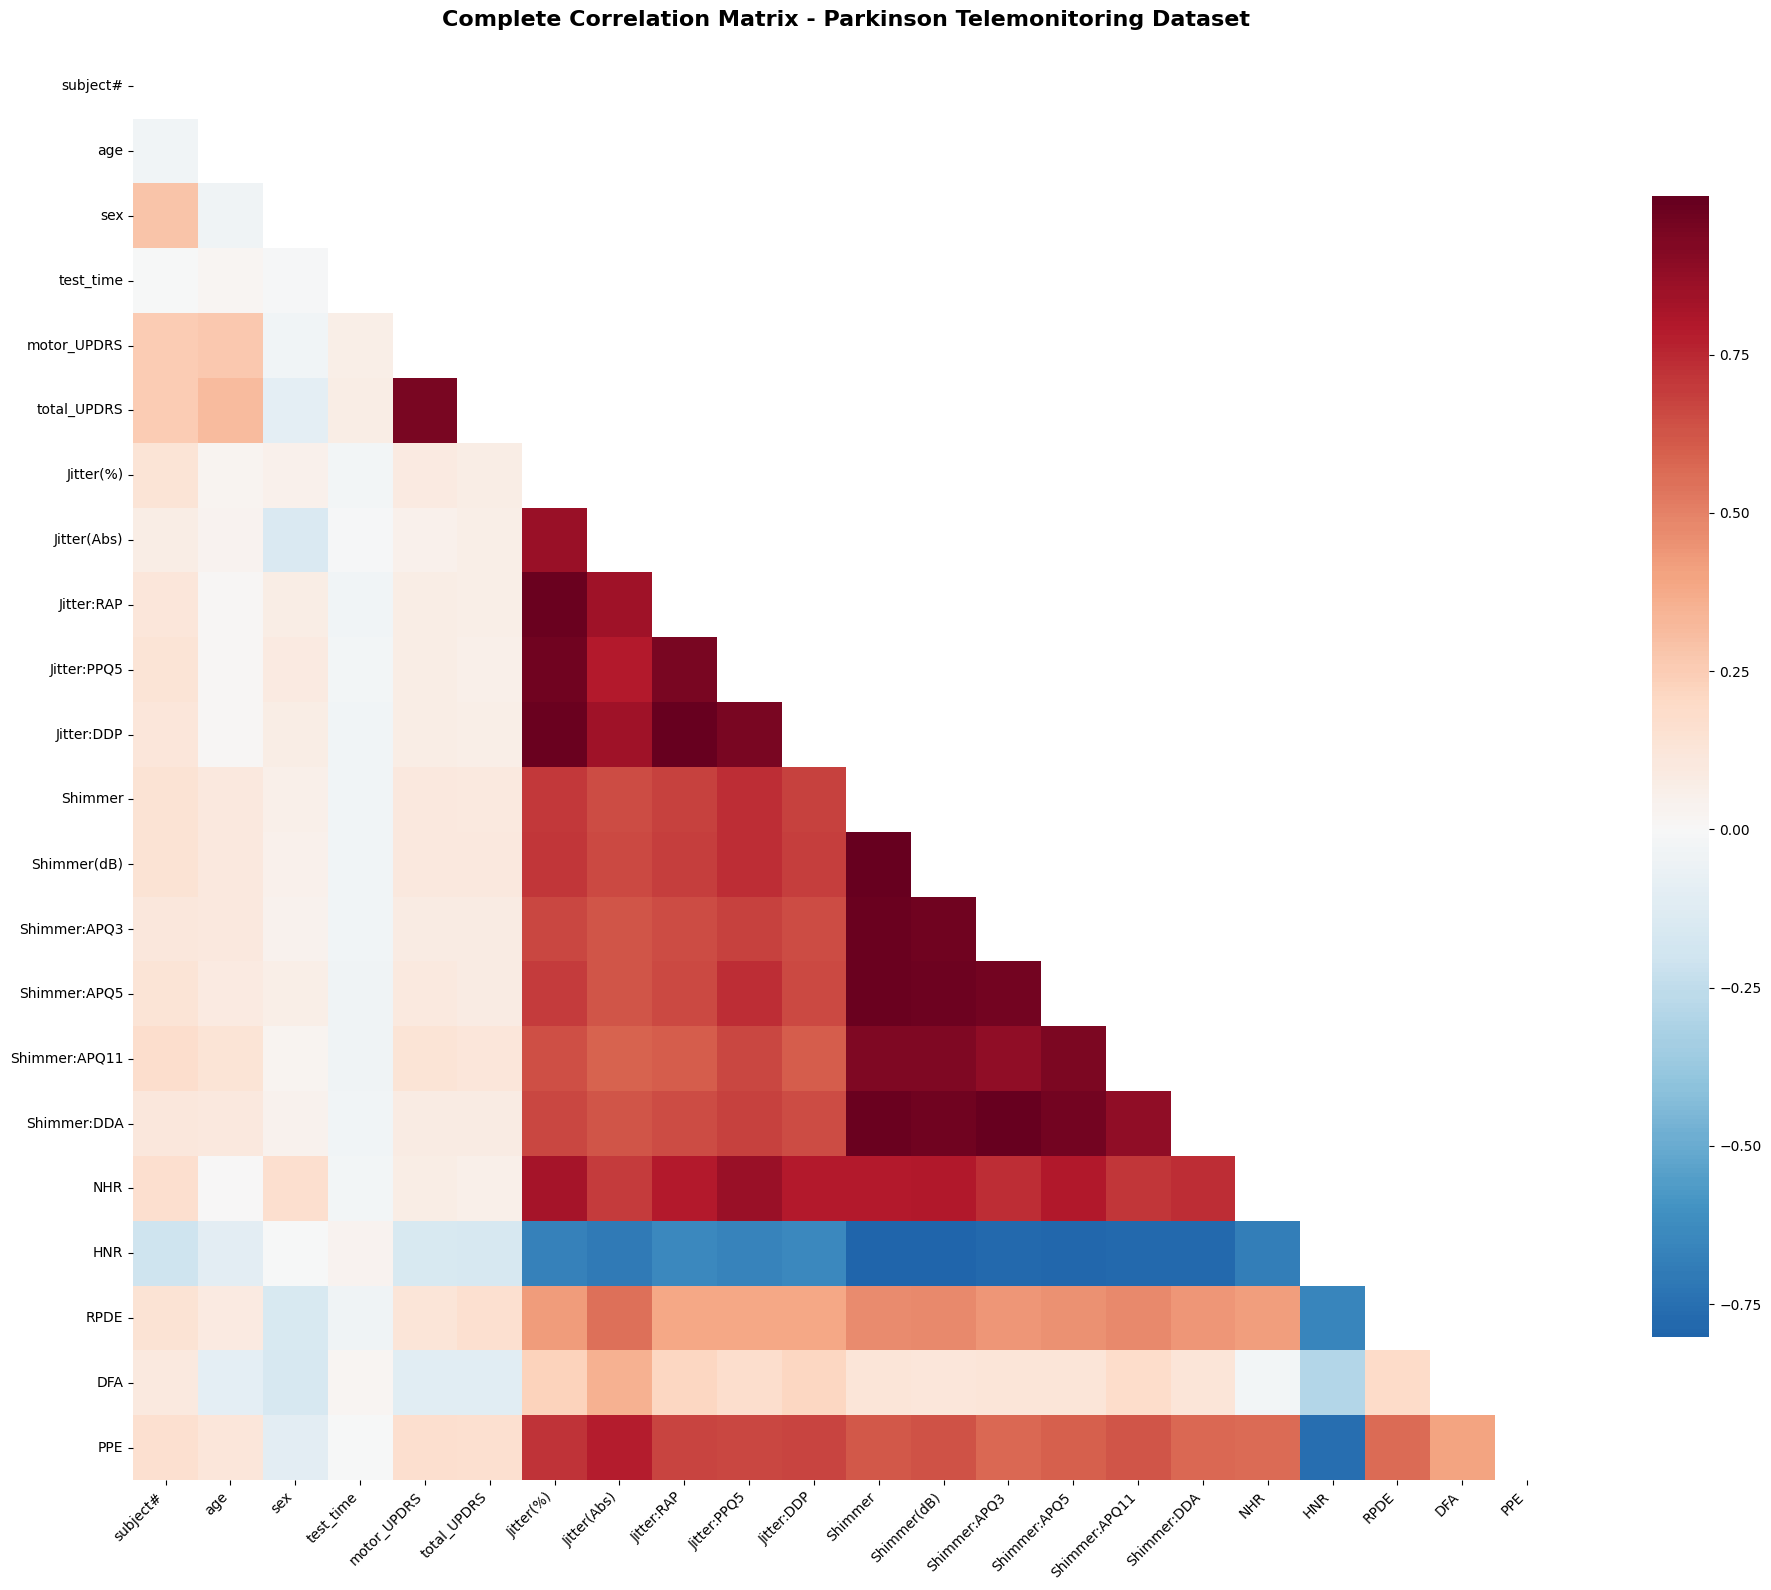

Focused correlation analysis with target variables


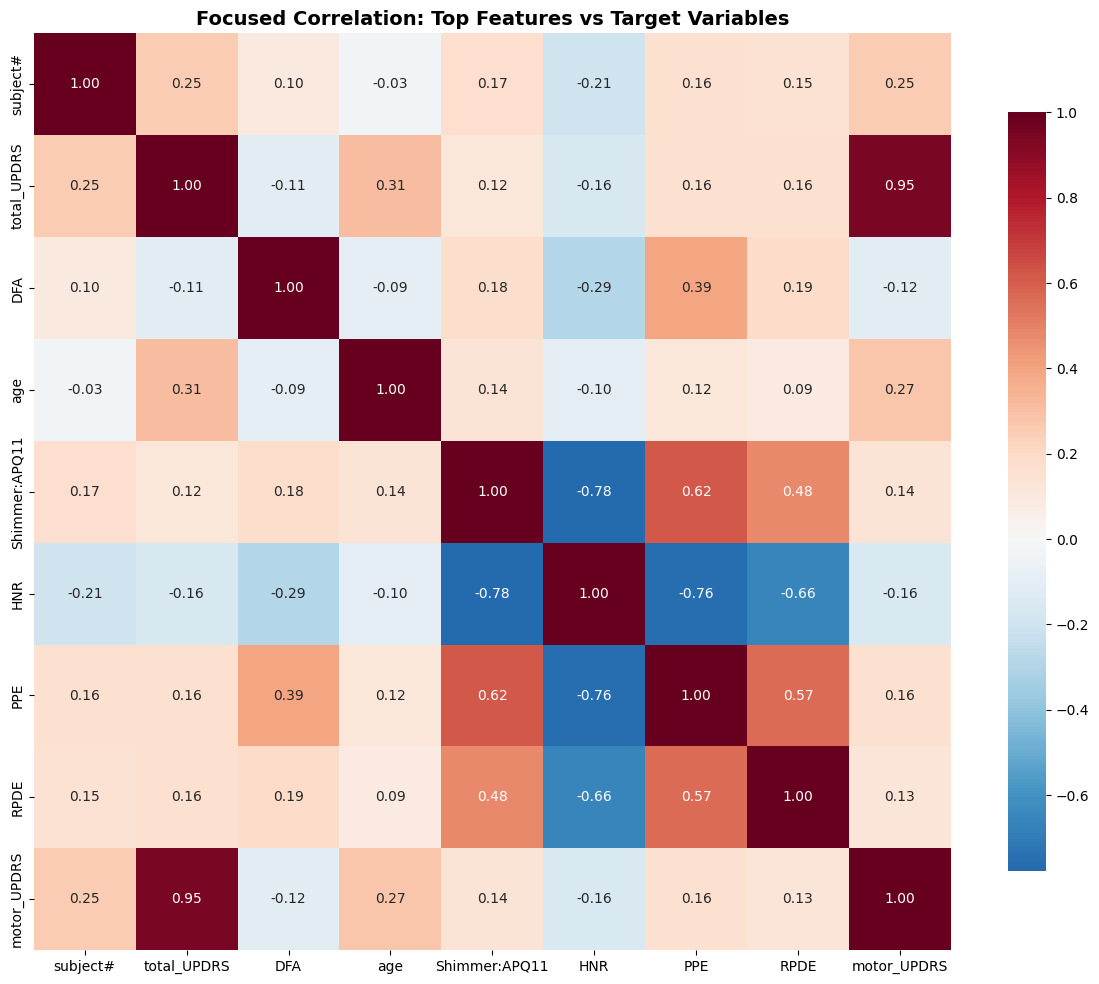

In [ ]:
print("CORRELATION VISUALIZATION")

# Create complete correlation heatmap
plt.figure(figsize=(20, 16))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))  # Mask upper triangle

sns.heatmap(correlation_matrix,
            mask=mask,
            annot=False,
            cmap='RdBu_r',
            center=0,
            square=True,
            cbar_kws={"shrink": 0.8})
plt.title('Complete Correlation Matrix - Parkinson Telemonitoring Dataset',
          fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Create focused heatmap for top correlated features with targets
print("Focused correlation analysis with target variables")

# Get top features correlated with both targets
top_motor_features = motor_updrs_corr.index[1:9]  # Skip target itself
top_total_features = total_updrs_corr.index[1:9]  # Skip target itself
top_features = list(set(list(top_motor_features) + list(top_total_features) + ['motor_UPDRS', 'total_UPDRS']))

focused_corr = correlation_matrix.loc[top_features, top_features]

plt.figure(figsize=(12, 10))
sns.heatmap(focused_corr,
            annot=True,
            cmap='RdBu_r',
            center=0,
            square=True,
            fmt='.2f',
            cbar_kws={"shrink": 0.8})
plt.title('Focused Correlation: Top Features vs Target Variables',
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

TARGET VARIABLE ANALYSIS


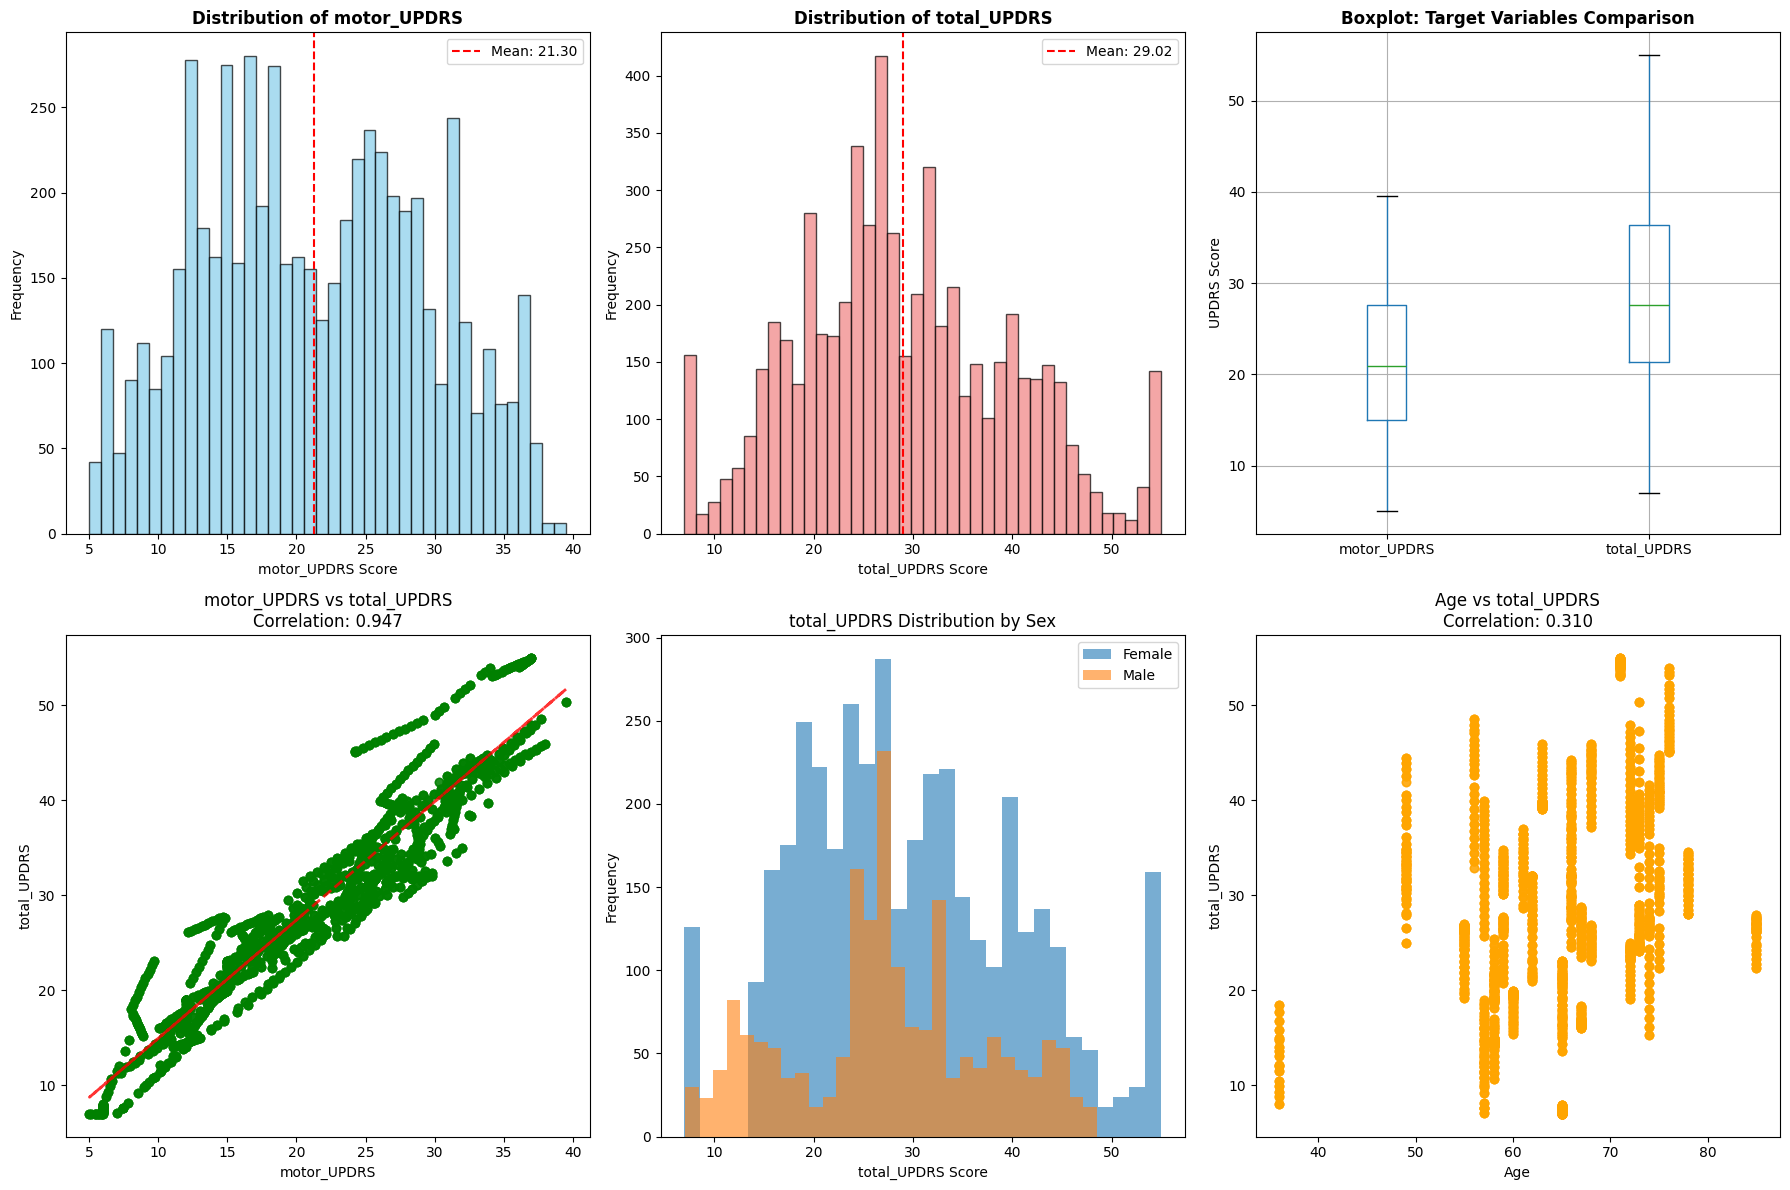

Statistical Summary of Target Variables:


,motor_UPDRS,total_UPDRS
count,5875.000000,5875.000000
mean,21.296229,29.018942
std,8.129282,10.700283
min,5.037700,7.000000
25%,15.000000,21.371000
50%,20.871000,27.576000
75%,27.596500,36.399000
max,39.511000,54.992000


Correlation between target variables: 0.9472


In [ ]:
print("TARGET VARIABLE ANALYSIS")

# Create comprehensive target analysis
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# motor_UPDRS distribution
axes[0,0].hist(df['motor_UPDRS'], bins=40, alpha=0.7, color='skyblue', edgecolor='black')
axes[0,0].set_title('Distribution of motor_UPDRS', fontweight='bold')
axes[0,0].set_xlabel('motor_UPDRS Score')
axes[0,0].set_ylabel('Frequency')
axes[0,0].axvline(df['motor_UPDRS'].mean(), color='red', linestyle='--', label=f'Mean: {df["motor_UPDRS"].mean():.2f}')
axes[0,0].legend()

# total_UPDRS distribution
axes[0,1].hist(df['total_UPDRS'], bins=40, alpha=0.7, color='lightcoral', edgecolor='black')
axes[0,1].set_title('Distribution of total_UPDRS', fontweight='bold')
axes[0,1].set_xlabel('total_UPDRS Score')
axes[0,1].set_ylabel('Frequency')
axes[0,1].axvline(df['total_UPDRS'].mean(), color='red', linestyle='--', label=f'Mean: {df["total_UPDRS"].mean():.2f}')
axes[0,1].legend()

# Boxplot comparison
df[['motor_UPDRS', 'total_UPDRS']].boxplot(ax=axes[0,2])
axes[0,2].set_title('Boxplot: Target Variables Comparison', fontweight='bold')
axes[0,2].set_ylabel('UPDRS Score')

# Scatter plot: motor_UPDRS vs total_UPDRS
axes[1,0].scatter(df['motor_UPDRS'], df['total_UPDRS'], alpha=0.5, color='green')
axes[1,0].set_xlabel('motor_UPDRS')
axes[1,0].set_ylabel('total_UPDRS')
axes[1,0].set_title(f'motor_UPDRS vs total_UPDRS\nCorrelation: {df["motor_UPDRS"].corr(df["total_UPDRS"]):.3f}')

# Add correlation line
z = np.polyfit(df['motor_UPDRS'], df['total_UPDRS'], 1)
p = np.poly1d(z)
axes[1,0].plot(df['motor_UPDRS'], p(df['motor_UPDRS']), "r--", alpha=0.8, linewidth=2)

# Distribution by sex (if available)
if 'sex' in df.columns:
    sex_mapping = {0: 'Female', 1: 'Male'} if df['sex'].nunique() == 2 else 'Unknown'
    for sex_val in df['sex'].unique():
        sex_data = df[df['sex'] == sex_val]
        label = sex_mapping.get(sex_val, f'Sex {sex_val}')
        axes[1,1].hist(sex_data['total_UPDRS'], bins=30, alpha=0.6, label=label)
    axes[1,1].set_title('total_UPDRS Distribution by Sex')
    axes[1,1].set_xlabel('total_UPDRS Score')
    axes[1,1].set_ylabel('Frequency')
    axes[1,1].legend()
else:
    axes[1,1].hist(df['total_UPDRS'], bins=40, alpha=0.7, color='purple', edgecolor='black')
    axes[1,1].set_title('Alternative: total_UPDRS Distribution')
    axes[1,1].set_xlabel('total_UPDRS Score')
    axes[1,1].set_ylabel('Frequency')

# Age distribution vs UPDRS (if age available)
if 'age' in df.columns:
    axes[1,2].scatter(df['age'], df['total_UPDRS'], alpha=0.5, color='orange')
    axes[1,2].set_xlabel('Age')
    axes[1,2].set_ylabel('total_UPDRS')
    axes[1,2].set_title(f'Age vs total_UPDRS\nCorrelation: {df["age"].corr(df["total_UPDRS"]):.3f}')
else:
    # Alternative: test_time vs UPDRS
    if 'test_time' in df.columns:
        axes[1,2].scatter(df['test_time'], df['total_UPDRS'], alpha=0.5, color='brown')
        axes[1,2].set_xlabel('Test Time')
        axes[1,2].set_ylabel('total_UPDRS')
        axes[1,2].set_title(f'Test Time vs total_UPDRS\nCorrelation: {df["test_time"].corr(df["total_UPDRS"]):.3f}')

plt.tight_layout()
plt.show()

# Statistical summary of targets
print("Statistical Summary of Target Variables:")
target_stats = df[['motor_UPDRS', 'total_UPDRS']].describe()
display(target_stats)

print("Correlation between target variables:", round(df['motor_UPDRS'].corr(df['total_UPDRS']), 4))

FEATURE IMPORTANCE ANALYSIS - CORRELATION METHOD
Top 20 Most Important Features (Correlation Method):


,Correlation with motor_UPDRS,Correlation with total_UPDRS,Average Correlation
age,0.273665,0.310290,0.291977
subject#,0.252919,0.253643,0.253281
HNR,0.157029,0.162117,0.159573
PPE,0.162433,0.156195,0.159314
RPDE,0.128607,0.156897,0.142752
Shimmer:APQ11,0.136560,0.120838,0.128699
DFA,0.116242,0.113475,0.114859
Shimmer(dB),0.110076,0.098790,0.104433
Shimmer,0.102349,0.092141,0.097245
Shimmer:APQ5,0.092105,0.083467,0.087786


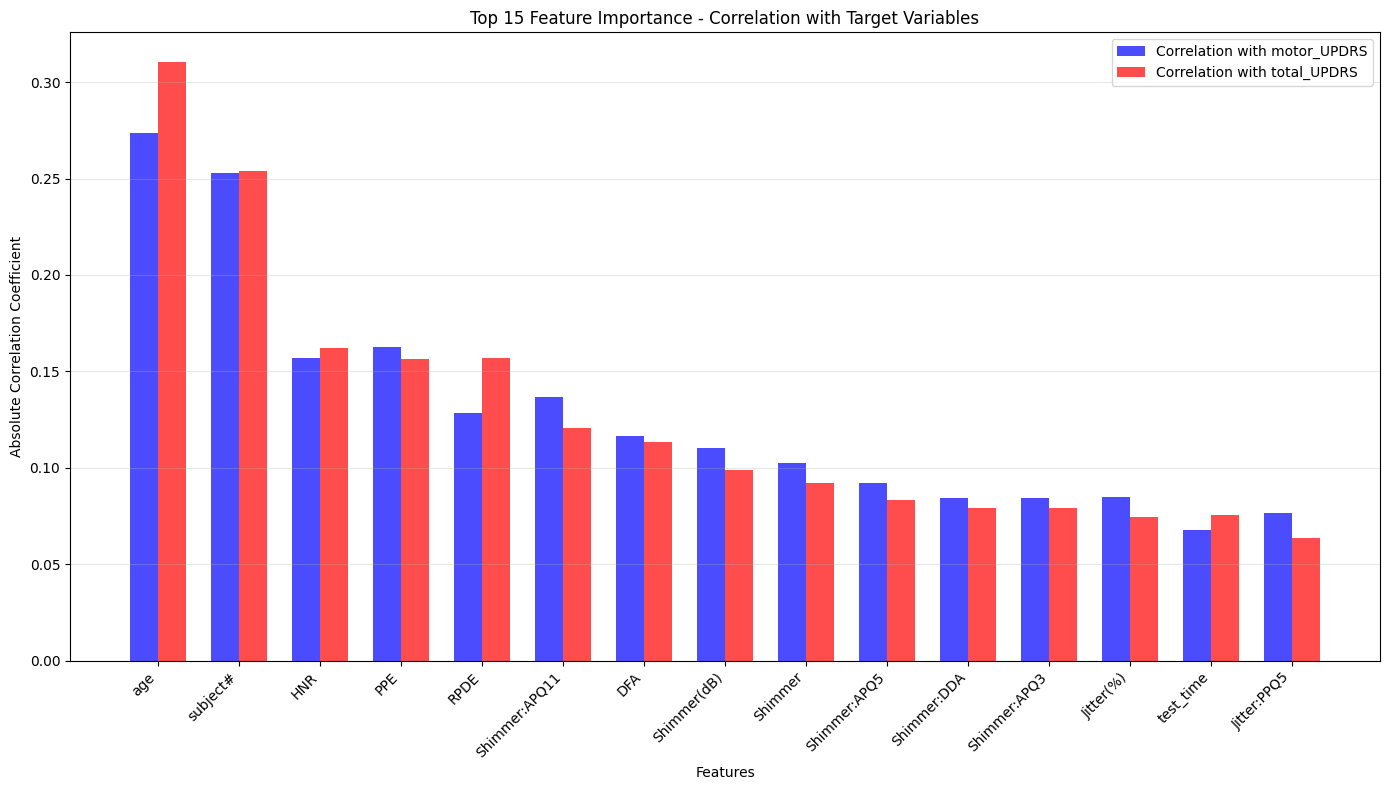

Key features identified for disease progression prediction:
1. age (Avg correlation: 0.292)
2. subject# (Avg correlation: 0.253)
3. HNR (Avg correlation: 0.160)
4. PPE (Avg correlation: 0.159)
5. RPDE (Avg correlation: 0.143)


In [ ]:
print("FEATURE IMPORTANCE ANALYSIS - CORRELATION METHOD")

# Create combined feature importance score
feature_importance_corr = pd.DataFrame({
    'Correlation with motor_UPDRS': correlation_matrix['motor_UPDRS'].abs(),
    'Correlation with total_UPDRS': correlation_matrix['total_UPDRS'].abs()
})

# Calculate average correlation with both targets
feature_importance_corr['Average Correlation'] = (
    feature_importance_corr['Correlation with motor_UPDRS'] +
    feature_importance_corr['Correlation with total_UPDRS']
) / 2

# Remove target variables from ranking
feature_importance_corr = feature_importance_corr.drop(['motor_UPDRS', 'total_UPDRS'])

# Sort by average correlation (most important first)
feature_importance_corr = feature_importance_corr.sort_values('Average Correlation', ascending=False)

print("Top 20 Most Important Features (Correlation Method):")
display(feature_importance_corr.head(20))

# Visualize top features
plt.figure(figsize=(14, 8))
top_15_features = feature_importance_corr.head(15)

x_pos = np.arange(len(top_15_features))
width = 0.35

plt.bar(x_pos - width/2, top_15_features['Correlation with motor_UPDRS'],
        width, label='Correlation with motor_UPDRS', alpha=0.7, color='blue')
plt.bar(x_pos + width/2, top_15_features['Correlation with total_UPDRS'],
        width, label='Correlation with total_UPDRS', alpha=0.7, color='red')

plt.xlabel('Features')
plt.ylabel('Absolute Correlation Coefficient')
plt.title('Top 15 Feature Importance - Correlation with Target Variables')
plt.xticks(x_pos, top_15_features.index, rotation=45, ha='right')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("Key features identified for disease progression prediction:")
top_5_features = feature_importance_corr.head(5)
for i, (feature, scores) in enumerate(top_5_features.iterrows(), 1):
    print(f"{i}. {feature} (Avg correlation: {scores['Average Correlation']:.3f})")

In [ ]:
print("FEATURE IMPORTANCE ANALYSIS - STATISTICAL METHOD")

# Prepare data for statistical analysis
X = df.drop(['motor_UPDRS', 'total_UPDRS'], axis=1)
y_motor = df['motor_UPDRS']
y_total = df['total_UPDRS']

# Add constant for statsmodels
X_with_const = sm.add_constant(X)

print("Statistical Feature Importance for motor_UPDRS:")
# Fit OLS model for motor_UPDRS
model_motor = sm.OLS(y_motor, X_with_const).fit()

# Extract coefficients and p-values
motor_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model_motor.params[1:],
    'P Value': model_motor.pvalues[1:],
    'Absolute Coefficient': np.abs(model_motor.params[1:])
})

# Sort by absolute coefficient value
motor_importance = motor_importance.sort_values('Absolute Coefficient', ascending=False)

print("Top 15 Features for motor_UPDRS Prediction:")
display(motor_importance.head(15))

print("Statistically Significant Features for motor_UPDRS (p < 0.05):")
significant_motor = motor_importance[motor_importance['P Value'] < 0.05]
display(significant_motor.head(15))

print("\nStatistical Feature Importance for total_UPDRS:")
# Fit OLS model for total_UPDRS
model_total = sm.OLS(y_total, X_with_const).fit()

# Extract coefficients and p-values
total_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model_total.params[1:],
    'P Value': model_total.pvalues[1:],
    'Absolute Coefficient': np.abs(model_total.params[1:])
})

# Sort by absolute coefficient value
total_importance = total_importance.sort_values('Absolute Coefficient', ascending=False)

print("Top 15 Features for total_UPDRS Prediction:")
display(total_importance.head(15))

print("Statistically Significant Features for total_UPDRS (p < 0.05):")
significant_total = total_importance[total_importance['P Value'] < 0.05]
display(significant_total.head(15))

FEATURE IMPORTANCE ANALYSIS - STATISTICAL METHOD
Statistical Feature Importance for motor_UPDRS:
Top 15 Features for motor_UPDRS Prediction:


,Feature,Coefficient,P Value,Absolute Coefficient
Jitter(Abs),Jitter(Abs),-51711.210606,2.111345e-12,51711.210606
Jitter:RAP,Jitter:RAP,-28434.465293,4.113713e-01,28434.465293
Jitter:DDP,Jitter:DDP,9669.942742,4.020108e-01,9669.942742
Shimmer:APQ3,Shimmer:APQ3,-1099.551756,9.747693e-01,1099.551756
Shimmer:DDA,Shimmer:DDA,327.192087,9.774756e-01,327.192087
Jitter:PPQ5,Jitter:PPQ5,-206.515830,1.411247e-01,206.515830
Jitter(%),Jitter(%),83.948811,5.949958e-01,83.948811
Shimmer,Shimmer,53.848490,2.628462e-01,53.848490
Shimmer:APQ5,Shimmer:APQ5,-47.450917,2.475727e-01,47.450917
Shimmer:APQ11,Shimmer:APQ11,43.290106,1.886013e-02,43.290106


Statistically Significant Features for motor_UPDRS (p < 0.05):


,Feature,Coefficient,P Value,Absolute Coefficient
Jitter(Abs),Jitter(Abs),-51711.210606,2.111345e-12,51711.210606
Shimmer:APQ11,Shimmer:APQ11,43.290106,1.886013e-02,43.290106
DFA,DFA,-26.849109,3.873727e-54,26.849109
NHR,NHR,-16.123531,4.870322e-04,16.123531
PPE,PPE,16.114628,1.116899e-13,16.114628
sex,sex,-2.530380,3.495889e-25,2.530380
HNR,HNR,-0.329542,1.293874e-10,0.329542
age,age,0.202506,1.388019e-71,0.202506
subject#,subject#,0.179284,5.996280e-98,0.179284
test_time,test_time,0.011015,4.902554e-10,0.011015



Statistical Feature Importance for total_UPDRS:
Top 15 Features for total_UPDRS Prediction:


,Feature,Coefficient,P Value,Absolute Coefficient
Jitter(Abs),Jitter(Abs),-44609.458094,2.392015e-06,44609.458094
Jitter:RAP,Jitter:RAP,-26029.794280,5.588732e-01,26029.794280
Shimmer:APQ3,Shimmer:APQ3,-14997.983334,7.373936e-01,14997.983334
Jitter:DDP,Jitter:DDP,9062.351905,5.415623e-01,9062.351905
Shimmer:DDA,Shimmer:DDA,4949.343630,7.399232e-01,4949.343630
Jitter(%),Jitter(%),-255.549336,2.084807e-01,255.549336
Jitter:PPQ5,Jitter:PPQ5,-166.919255,3.551917e-01,166.919255
Shimmer:APQ5,Shimmer:APQ5,49.607075,3.474362e-01,49.607075
DFA,DFA,-36.339999,1.342359e-59,36.339999
NHR,NHR,-23.717217,6.690264e-05,23.717217


Statistically Significant Features for total_UPDRS (p < 0.05):


,Feature,Coefficient,P Value,Absolute Coefficient
Jitter(Abs),Jitter(Abs),-44609.458094,2.392015e-06,44609.458094
DFA,DFA,-36.339999,1.342359e-59,36.339999
NHR,NHR,-23.717217,6.690264e-05,23.717217
PPE,PPE,15.485484,2.815037e-08,15.485484
sex,sex,-4.812011,1.860842e-52,4.812011
HNR,HNR,-0.485772,1.829720e-13,0.485772
age,age,0.318671,8.741900e-105,0.318671
subject#,subject#,0.263599,6.254643e-126,0.263599
test_time,test_time,0.015940,2.646543e-12,0.015940


ANALYZING RELATIONSHIPS WITH TOP FEATURES
Analyzing relationships with top 4 features: ['age', 'subject#', 'HNR', 'PPE']


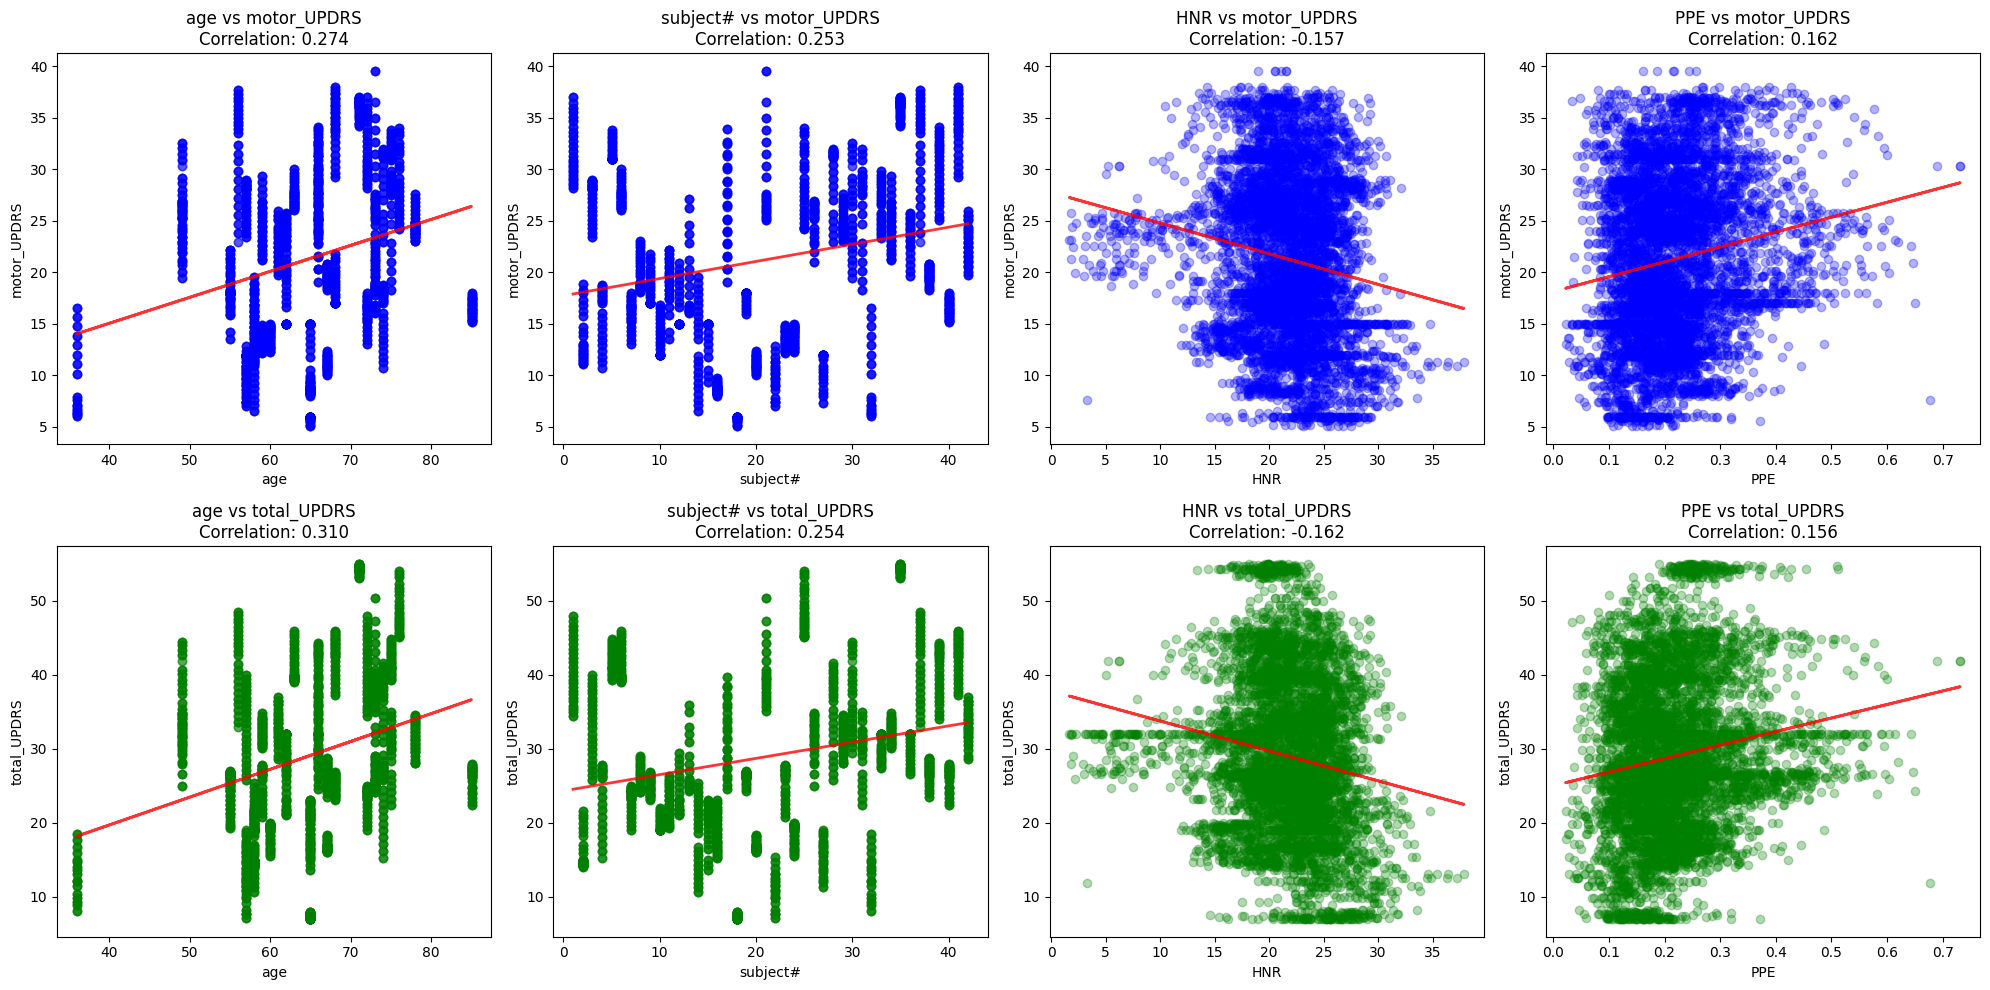

Statistical Summary of Top 4 Features:


,age,subject#,HNR,PPE
count,5875.000000,5875.000000,5875.000000,5875.000000
mean,64.804936,21.494128,21.679495,0.219589
std,8.821524,12.372279,4.291096,0.091498
min,36.000000,1.000000,1.659000,0.021983
25%,58.000000,10.000000,19.406000,0.156340
50%,65.000000,22.000000,21.920000,0.205500
75%,72.000000,33.000000,24.444000,0.264490
max,85.000000,42.000000,37.875000,0.731730


Distribution of Top Features:


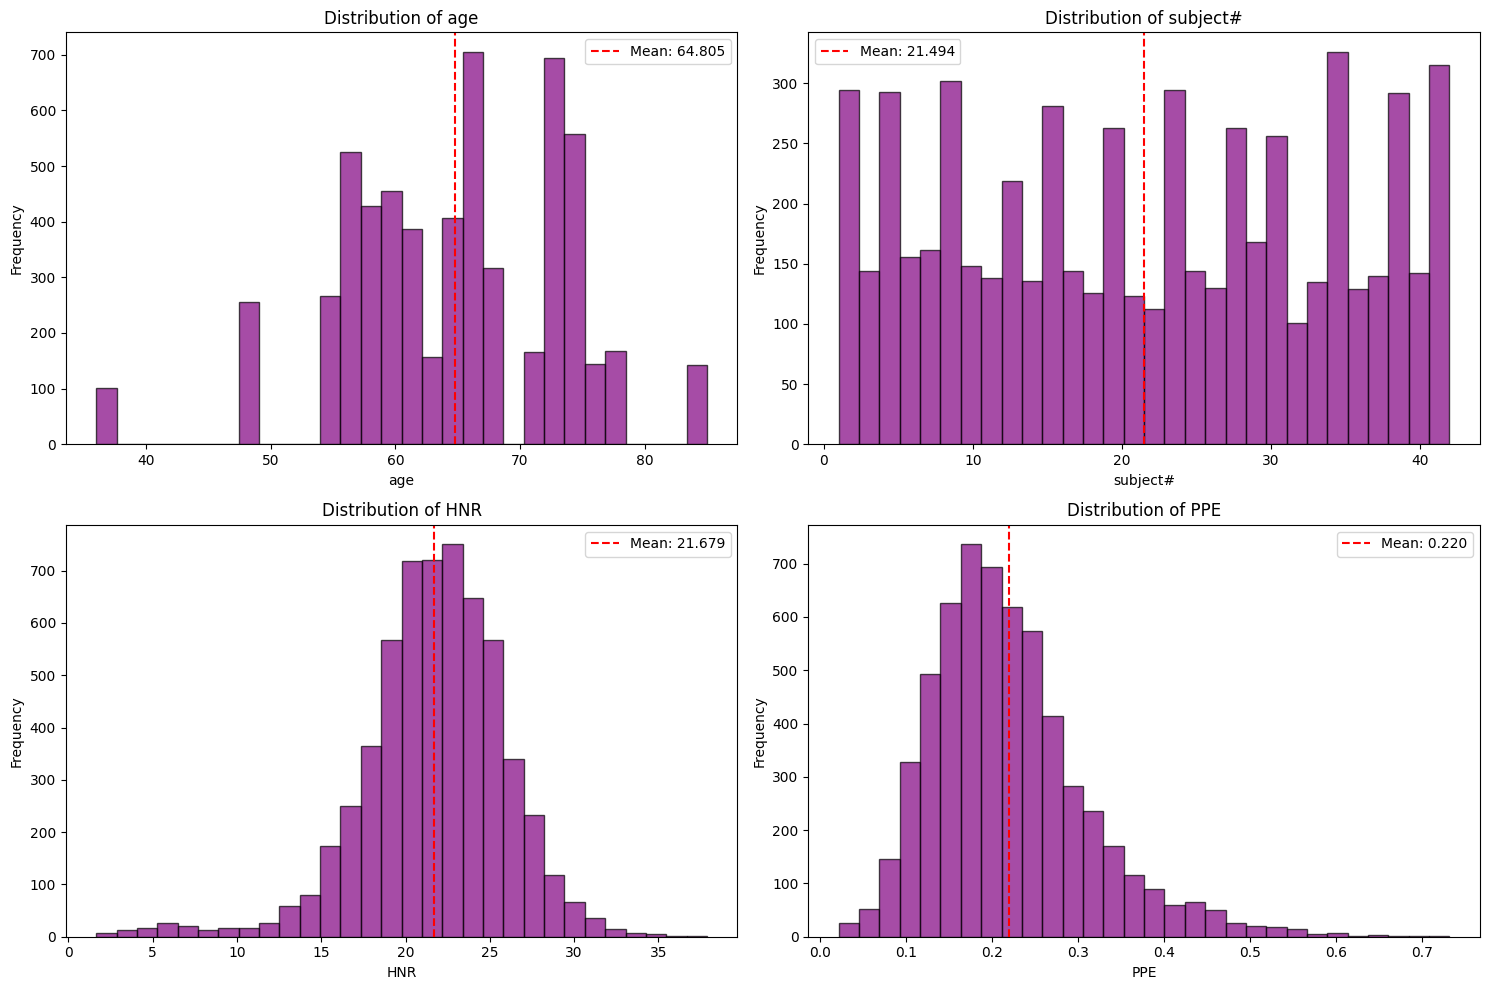

In [ ]:
print("ANALYZING RELATIONSHIPS WITH TOP FEATURES")

# Get top 4 features from correlation analysis
top_4_features = feature_importance_corr.head(4).index

print("Analyzing relationships with top 4 features:", list(top_4_features))

# Create scatter plots for top features vs targets
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for i, feature in enumerate(top_4_features):
    # Plot vs motor_UPDRS
    axes[0, i].scatter(df[feature], df['motor_UPDRS'], alpha=0.3, color='blue')
    axes[0, i].set_xlabel(feature)
    axes[0, i].set_ylabel('motor_UPDRS')
    corr_motor = df[feature].corr(df['motor_UPDRS'])
    axes[0, i].set_title(f'{feature} vs motor_UPDRS\nCorrelation: {corr_motor:.3f}')

    # Add trend line
    z_motor = np.polyfit(df[feature], df['motor_UPDRS'], 1)
    p_motor = np.poly1d(z_motor)
    axes[0, i].plot(df[feature], p_motor(df[feature]), "r-", alpha=0.8, linewidth=2)

    # Plot vs total_UPDRS
    axes[1, i].scatter(df[feature], df['total_UPDRS'], alpha=0.3, color='green')
    axes[1, i].set_xlabel(feature)
    axes[1, i].set_ylabel('total_UPDRS')
    corr_total = df[feature].corr(df['total_UPDRS'])
    axes[1, i].set_title(f'{feature} vs total_UPDRS\nCorrelation: {corr_total:.3f}')

    # Add trend line
    z_total = np.polyfit(df[feature], df['total_UPDRS'], 1)
    p_total = np.poly1d(z_total)
    axes[1, i].plot(df[feature], p_total(df[feature]), "r-", alpha=0.8, linewidth=2)

plt.tight_layout()
plt.show()

# Statistical summary of top features
print("Statistical Summary of Top 4 Features:")
top_features_stats = df[list(top_4_features)].describe()
display(top_features_stats)

# Analyze feature distributions
print("Distribution of Top Features:")
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

for i, feature in enumerate(top_4_features):
    axes[i].hist(df[feature], bins=30, alpha=0.7, color='purple', edgecolor='black')
    axes[i].set_title(f'Distribution of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')
    axes[i].axvline(df[feature].mean(), color='red', linestyle='--',
                   label=f'Mean: {df[feature].mean():.3f}')
    axes[i].legend()

plt.tight_layout()
plt.show()

In [ ]:
print("STEP 2 COMPLETION: EXPLORATORY DATA ANALYSIS SUMMARY")

print("EDA TASKS COMPLETED:")
eda_tasks = [
    "Correlation analysis among all features",
    "Target variable distribution analysis",
    "Feature importance identification using correlation method",
    "Feature importance identification using statistical method",
    "Relationship analysis between top features and targets",
    "Visualization of key patterns and relationships"
]

for task in eda_tasks:
    print("✓", task)

print("\nKEY INSIGHTS DISCOVERED:")

# Most important features
top_features = feature_importance_corr.head(5)
print("Top 5 features affecting disease progression:")
for i, (feature, scores) in enumerate(top_features.iterrows(), 1):
    print(f"  {i}. {feature} (avg correlation: {scores['Average Correlation']:.3f})")

# Target variable insights
print(f"\nTarget Variable Statistics:")
print(f"  motor_UPDRS range: {df['motor_UPDRS'].min():.1f} to {df['motor_UPDRS'].max():.1f}")
print(f"  total_UPDRS range: {df['total_UPDRS'].min():.1f} to {df['total_UPDRS'].max():.1f}")
print(f"  Correlation between targets: {df['motor_UPDRS'].corr(df['total_UPDRS']):.3f}")

# Data quality insights
print(f"\nData Quality Assessment:")
print(f"  Features analyzed: {len(df.columns)}")
print(f"  Records analyzed: {len(df)}")
print(f"  Highly correlated feature pairs (r > 0.8): {len(high_corr_pairs)}")

print("\nSTEP 2: EXPLORATORY DATA ANALYSIS COMPLETED SUCCESSFULLY")
print("Ready for Step 3: Limitations and Issues Analysis")

STEP 2 COMPLETION: EXPLORATORY DATA ANALYSIS SUMMARY
EDA TASKS COMPLETED:
✓ Correlation analysis among all features
✓ Target variable distribution analysis
✓ Feature importance identification using correlation method
✓ Feature importance identification using statistical method
✓ Relationship analysis between top features and targets
✓ Visualization of key patterns and relationships

KEY INSIGHTS DISCOVERED:
Top 5 features affecting disease progression:
  1. age (avg correlation: 0.292)
  2. subject# (avg correlation: 0.253)
  3. HNR (avg correlation: 0.160)
  4. PPE (avg correlation: 0.159)
  5. RPDE (avg correlation: 0.143)

Target Variable Statistics:
  motor_UPDRS range: 5.0 to 39.5
  total_UPDRS range: 7.0 to 55.0
  Correlation between targets: 0.947

Data Quality Assessment:
  Features analyzed: 22
  Records analyzed: 5875
  Highly correlated feature pairs (r > 0.8): 29

STEP 2: EXPLORATORY DATA ANALYSIS COMPLETED SUCCESSFULLY
Ready for Step 3: Limitations and Issues Analysis


In [ ]:
print("STEP 3: LIMITATIONS AND ISSUES ANALYSIS")
print("COMPREHENSIVE DATASET EVALUATION")

print("IDENTIFIED LIMITATIONS AND DATA QUALITY ISSUES:")

# 1. Data Quality Issues
print("1. DATA QUALITY ISSUES")

# Missing Values Assessment
print("   Missing Values Analysis:")
missing_total = df.isnull().sum().sum()
if missing_total > 0:
    print(f"   - Found {missing_total} missing values in the dataset")
    missing_cols = df.isnull().sum()
    missing_cols = missing_cols[missing_cols > 0]
    for col, count in missing_cols.items():
        percentage = (count / len(df)) * 100
        print(f"     * {col}: {count} missing values ({percentage:.2f}%)")
else:
    print("   - No missing values detected - Excellent data quality")

# Outlier Assessment
print("\n   Outlier Analysis:")
high_outlier_features = outlier_summary_df[outlier_summary_df['Outlier Percentage'] > 5]
if len(high_outlier_features) > 0:
    print(f"   - {len(high_outlier_features)} features have >5% outliers")
    for feature in high_outlier_features.head(5).index:
        pct = outlier_summary_df.loc[feature, 'Outlier Percentage']
        print(f"     * {feature}: {pct:.1f}% outliers")
else:
    print("   - Minimal outlier issues detected")

STEP 3: LIMITATIONS AND ISSUES ANALYSIS
COMPREHENSIVE DATASET EVALUATION
IDENTIFIED LIMITATIONS AND DATA QUALITY ISSUES:
1. DATA QUALITY ISSUES
   Missing Values Analysis:
   - No missing values detected - Excellent data quality

   Outlier Analysis:
   - 12 features have >5% outliers
     * NHR: 7.4% outliers
     * Jitter:PPQ5: 7.2% outliers
     * Jitter:RAP: 7.0% outliers
     * Jitter:DDP: 7.0% outliers
     * Jitter(%): 6.8% outliers


In [ ]:
print("2. DATA DISTRIBUTION AND SCALE ISSUES")

# Skewness Analysis
print("   Data Distribution Skewness:")
highly_skewed = df[numeric_columns].skew().abs()
highly_skewed = highly_skewed[highly_skewed > 1].sort_values(ascending=False)

if len(highly_skewed) > 0:
    print(f"   - {len(highly_skewed)} features are highly skewed (|skewness| > 1)")
    for feat, skew_val in highly_skewed.head(5).items():
        direction = "right-skewed" if df[feat].skew() > 0 else "left-skewed"
        print(f"     * {feat}: skewness = {skew_val:.2f} ({direction})")
else:
    print("   - No severely skewed distributions detected")

# Scale Issues
print("\n   Feature Scale Variations:")
numeric_stats = df.describe()
coefficient_of_variation = numeric_stats.loc['std'] / numeric_stats.loc['mean']
high_variance_features = coefficient_of_variation[coefficient_of_variation > 1].sort_values(ascending=False)

if len(high_variance_features) > 0:
    print(f"   - {len(high_variance_features)} features have high coefficient of variation (>1)")
    print("     These features may require scaling for modeling:")
    for feat, cov in high_variance_features.head(5).items():
        print(f"     * {feat}: CoV = {cov:.2f}")
else:
    print("   - Reasonable scale variations across features")

# Constant or Low Variance Features
print("\n   Low Variance Features:")
constant_features = []
low_variance_features = []
for col in numeric_columns:
    if df[col].nunique() == 1:
        constant_features.append(col)
    elif df[col].nunique() / len(df) < 0.01:  # Less than 1% unique values
        low_variance_features.append(col)

if constant_features:
    print(f"   - Constant features (only one value): {constant_features}")
if low_variance_features:
    print(f"   - Low variance features: {low_variance_features}")
if not constant_features and not low_variance_features:
    print("   - No constant or extremely low variance features detected")

2. DATA DISTRIBUTION AND SCALE ISSUES
   Data Distribution Skewness:
   - 13 features are highly skewed (|skewness| > 1)
     * Jitter:PPQ5: skewness = 7.59 (right-skewed)
     * Jitter:RAP: skewness = 6.95 (right-skewed)
     * Jitter:DDP: skewness = 6.95 (right-skewed)
     * NHR: skewness = 6.55 (right-skewed)
     * Jitter(%): skewness = 6.45 (right-skewed)

   Feature Scale Variations:
   - 5 features have high coefficient of variation (>1)
     These features may require scaling for modeling:
     * NHR: CoV = 1.86
     * sex: CoV = 1.47
     * Jitter:PPQ5: CoV = 1.14
     * Jitter:RAP: CoV = 1.05
     * Jitter:DDP: CoV = 1.05

   Low Variance Features:
   - Low variance features: ['subject#', 'age', 'sex']


In [ ]:
print("3. MULTICOLLINEARITY AND FEATURE RELATIONSHIP ISSUES")

# Multicollinearity Analysis
print("   Multicollinearity Assessment:")
if high_corr_pairs:
    print(f"   - Found {len(high_corr_pairs)} highly correlated feature pairs (r > 0.8)")
    print("     Top highly correlated pairs:")
    for i, (feat1, feat2, corr) in enumerate(high_corr_pairs[:8], 1):
        print(f"     {i}. {feat1} & {feat2}: r = {corr:.3f}")

    # Check if highly correlated pairs involve target variables
    target_corr_issues = []
    for feat1, feat2, corr in high_corr_pairs:
        if feat1 in ['motor_UPDRS', 'total_UPDRS'] or feat2 in ['motor_UPDRS', 'total_UPDRS']:
            target_corr_issues.append((feat1, feat2, corr))

    if target_corr_issues:
        print("\n   - Warning: High correlation detected with target variables")
        for feat1, feat2, corr in target_corr_issues:
            print(f"     * {feat1} & {feat2}: r = {corr:.3f}")
else:
    print("   - No severe multicollinearity issues detected")

# Feature-Target Relationship Strength
print("\n   Feature-Target Relationship Strength:")
weak_correlation_features = feature_importance_corr[feature_importance_corr['Average Correlation'] < 0.1]
if len(weak_correlation_features) > 0:
    print(f"   - {len(weak_correlation_features)} features show weak correlation with targets (r < 0.1)")
    print("     These may not be useful for prediction:")
    for feat in weak_correlation_features.head(5).index:
        avg_corr = weak_correlation_features.loc[feat, 'Average Correlation']
        print(f"     * {feat}: average correlation = {avg_corr:.3f}")
else:
    print("   - Most features show meaningful correlation with targets")

3. MULTICOLLINEARITY AND FEATURE RELATIONSHIP ISSUES
   Multicollinearity Assessment:
   - Found 29 highly correlated feature pairs (r > 0.8)
     Top highly correlated pairs:
     1. Shimmer:APQ3 & Shimmer:DDA: r = 1.000
     2. Jitter:RAP & Jitter:DDP: r = 1.000
     3. Shimmer & Shimmer(dB): r = 0.992
     4. Shimmer & Shimmer:APQ5: r = 0.985
     5. Jitter(%) & Jitter:DDP: r = 0.984
     6. Jitter(%) & Jitter:RAP: r = 0.984
     7. Shimmer & Shimmer:APQ3: r = 0.980
     8. Shimmer & Shimmer:DDA: r = 0.980

   - Warning: High correlation detected with target variables
     * motor_UPDRS & total_UPDRS: r = 0.947

   Feature-Target Relationship Strength:
   - 12 features show weak correlation with targets (r < 0.1)
     These may not be useful for prediction:
     * Shimmer: average correlation = 0.097
     * Shimmer:APQ5: average correlation = 0.088
     * Shimmer:DDA: average correlation = 0.082
     * Shimmer:APQ3: average correlation = 0.082
     * Jitter(%): average correlation =